## <span style="color:purple"> Test Data: Graph Time Series Plots </span>

### <span style="color:purple"> Plotting function </span>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

position_colours = {0: "tab:blue", 1: "tab:orange", 2: "tab:green"}

def plot_time_series(df, am_id, ylim_temp=None, ylim_sal=None, ylim_p=None, resample=None, start_time=None, end_time=None):
    # Sort through dataframe keys and extract the keys containing the specified borehole is (AMXX)
    df_bh = df[df["borehole"] == am_id]

    # Filter to time range if specified
    if start_time is not None:
        df_bh = df_bh[df_bh["time"] >= start_time]
    if end_time is not None:
        df_bh = df_bh[df_bh["time"] <= end_time]
        
    # Sort cats by median pressure to ensure consistent ordering across plots
    median_pressure = df_bh.groupby("cat")["pressure"].median().sort_values()
    cats = median_pressure.index.tolist()
    
    if len(cats) == 0:
        print(f"No data for {am_id}")
        return

    fig, (axT, axS, axP) = plt.subplots(3, 1, figsize=(12, 10), sharex=False)

    for i, cat_id in enumerate(cats):
        dfp = df_bh[df_bh["cat"] == cat_id]
        colour = position_colours[i]

        axT.plot(dfp["time"], dfp["in_situ_temperature_smooth"], lw=0.8, label=f"cat{cat_id}", color=colour)
        axS.plot(dfp["time"], dfp["practical_salinity_smooth"],    lw=0.8, label=f"cat{cat_id}", color=colour)
        axP.plot(dfp["time"], dfp["pressure"],    lw=0.8, label=f"cat{cat_id}", color=colour)

    axT.set_ylabel("In Situ Temperature (°C)")
    axS.set_ylabel("Practical Salinity (PSS78)")
    axP.set_ylabel("Pressure (dbar)")
    #axS.set_xlabel("Year")
    axT.set_title(f"{am_id} MicroCAT: Temperature & Salinity")

    axT.legend(ncols=3)
    axS.legend(ncols=3)
    axP.legend(ncols=3)

    if ylim_temp is not None: axT.set_ylim(*ylim_temp)
    if ylim_sal  is not None: axS.set_ylim(*ylim_sal)
    if ylim_p  is not None: axP.set_ylim(*ylim_p)

    axT.grid(True); axS.grid(True); axP.grid(True)
    plt.tight_layout()
    plt.show()

### <span style="color:purple"> Plot time series graphs of temp and salinity for each borehole location </span>

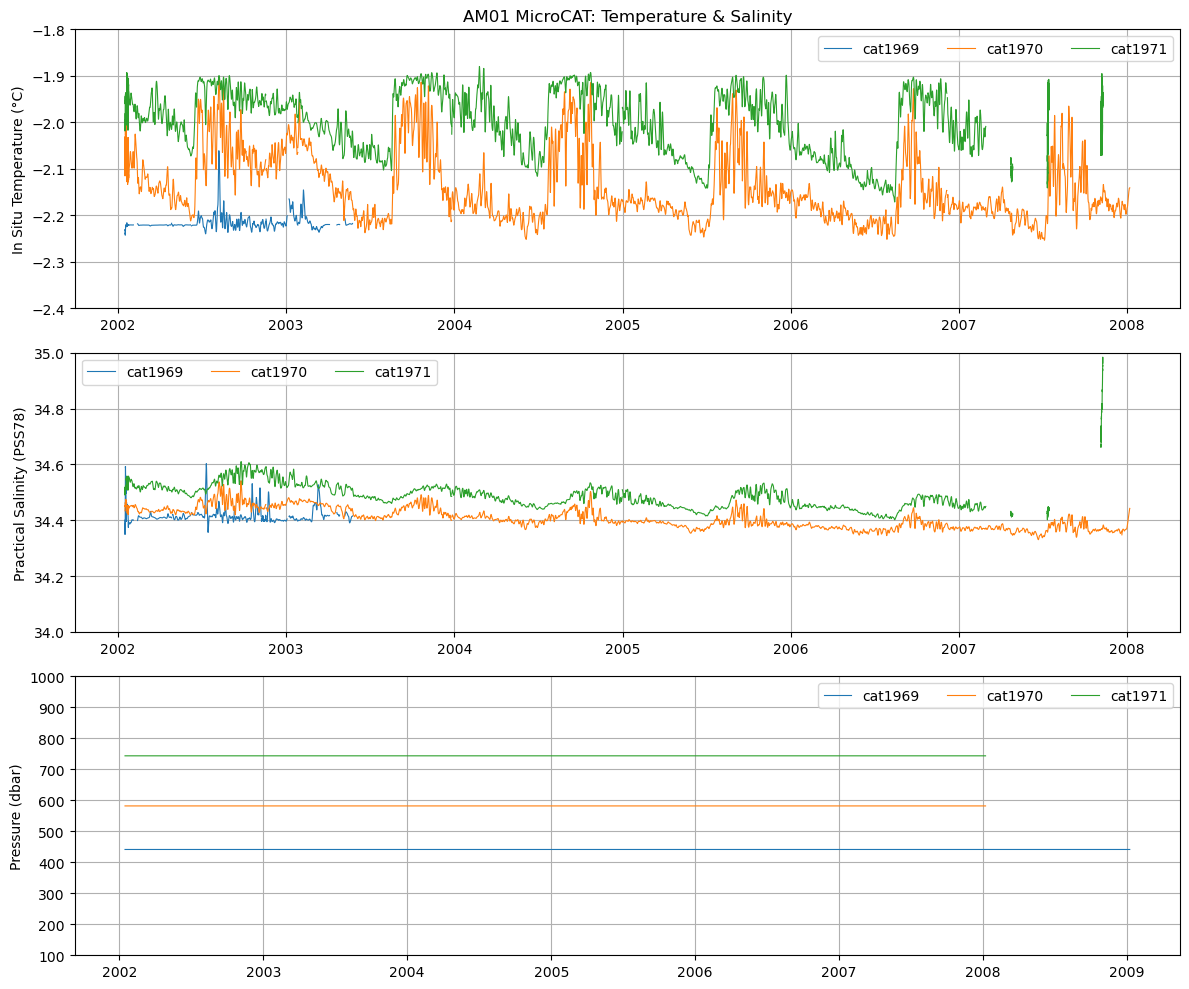

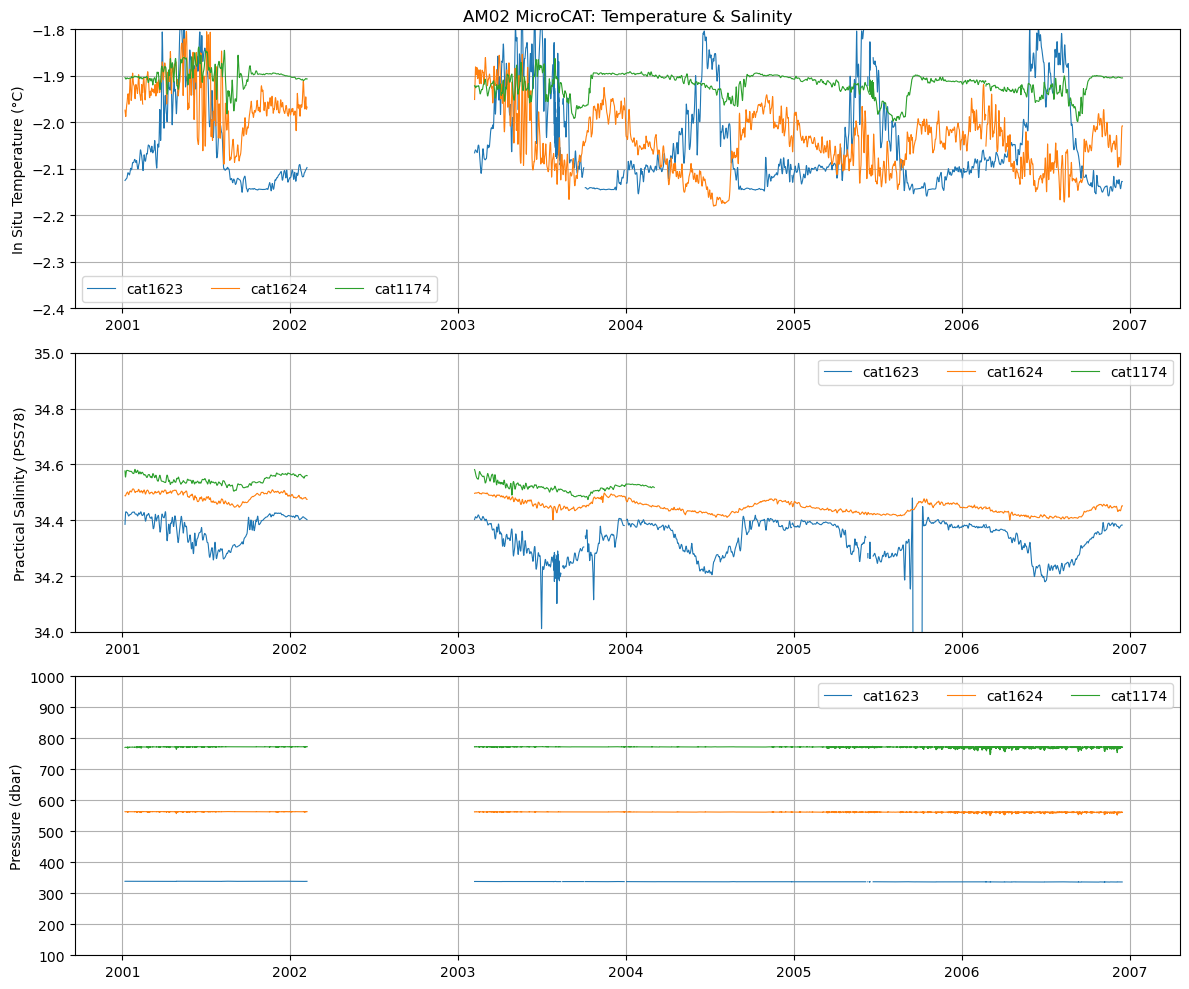

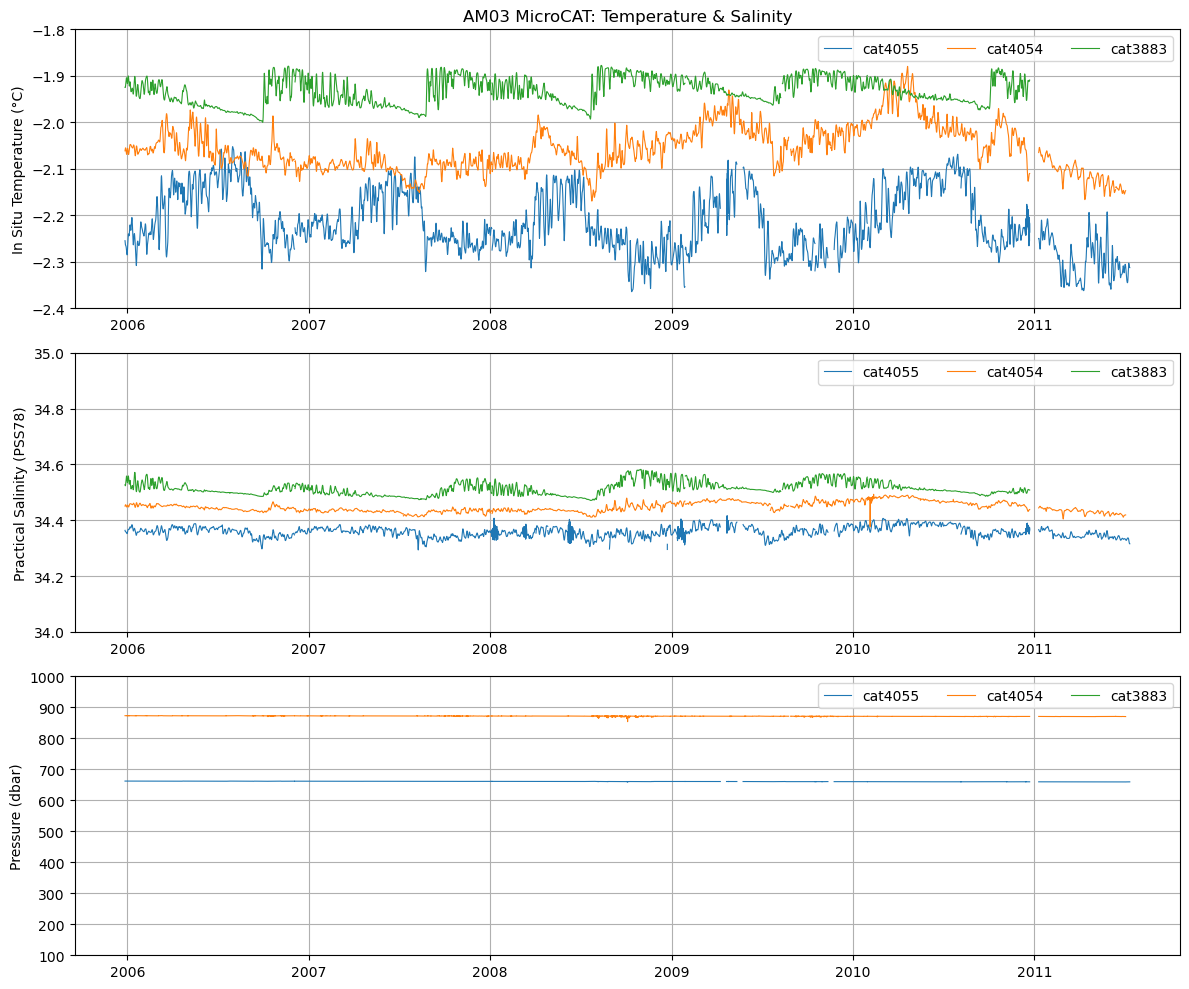

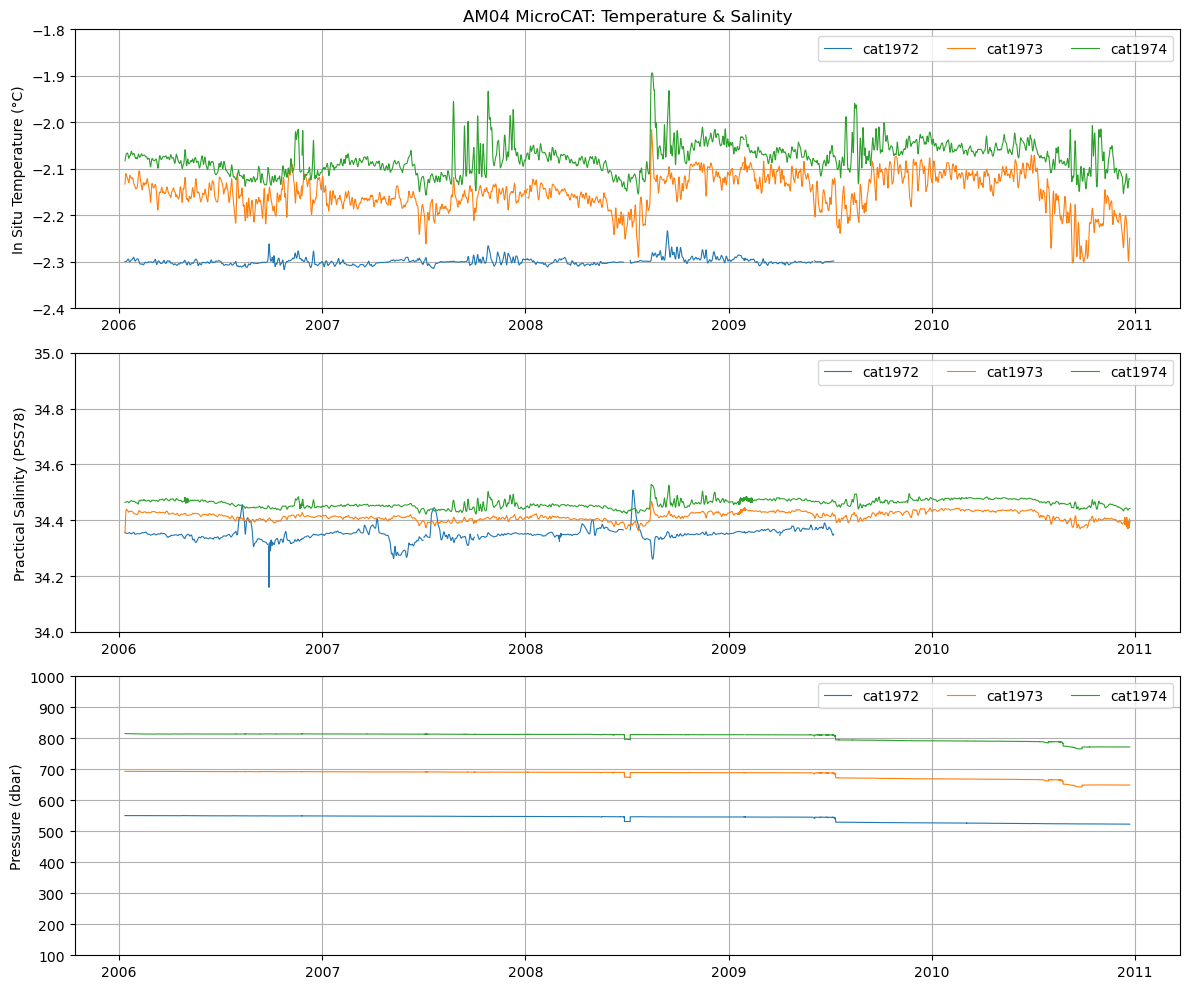

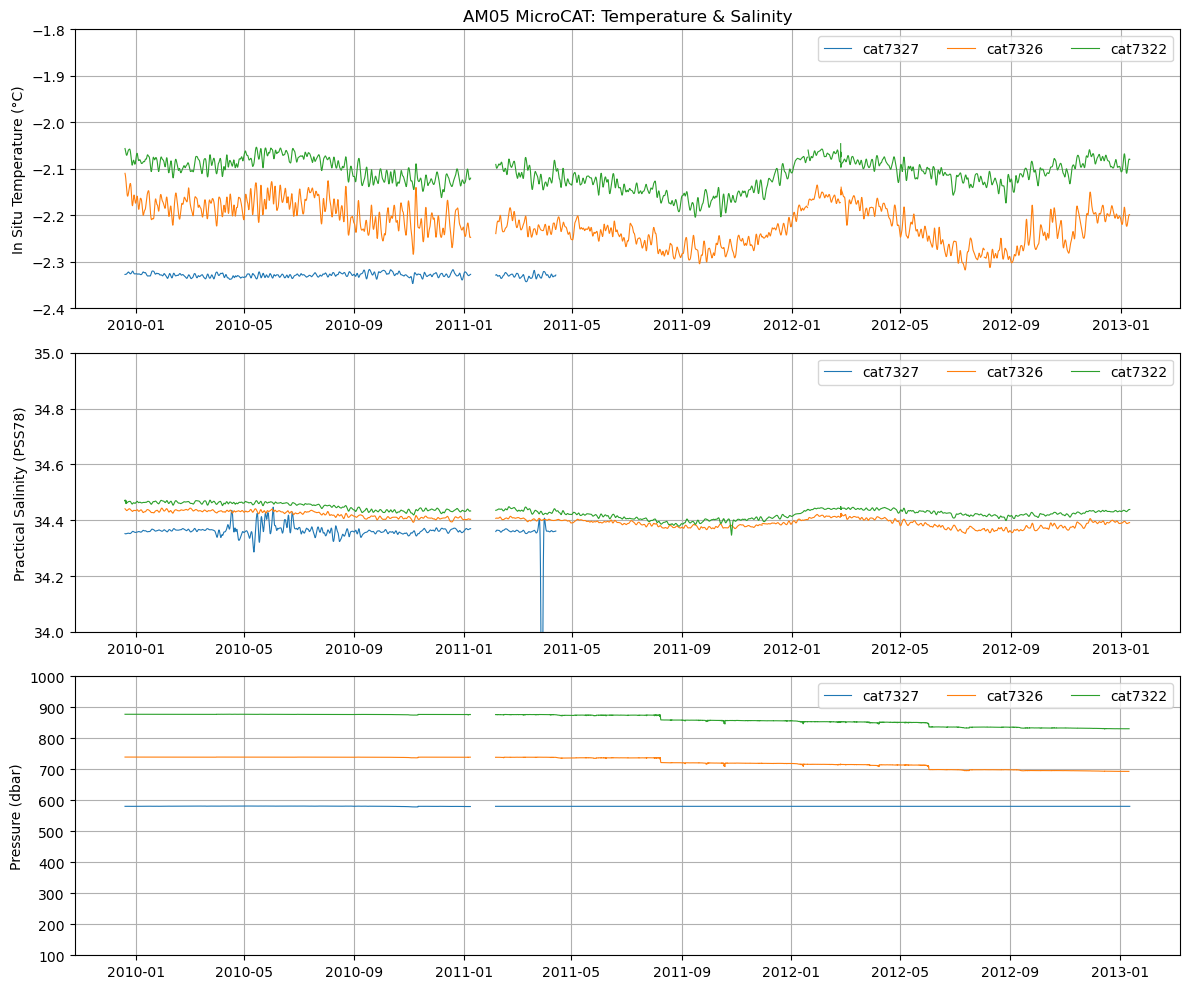

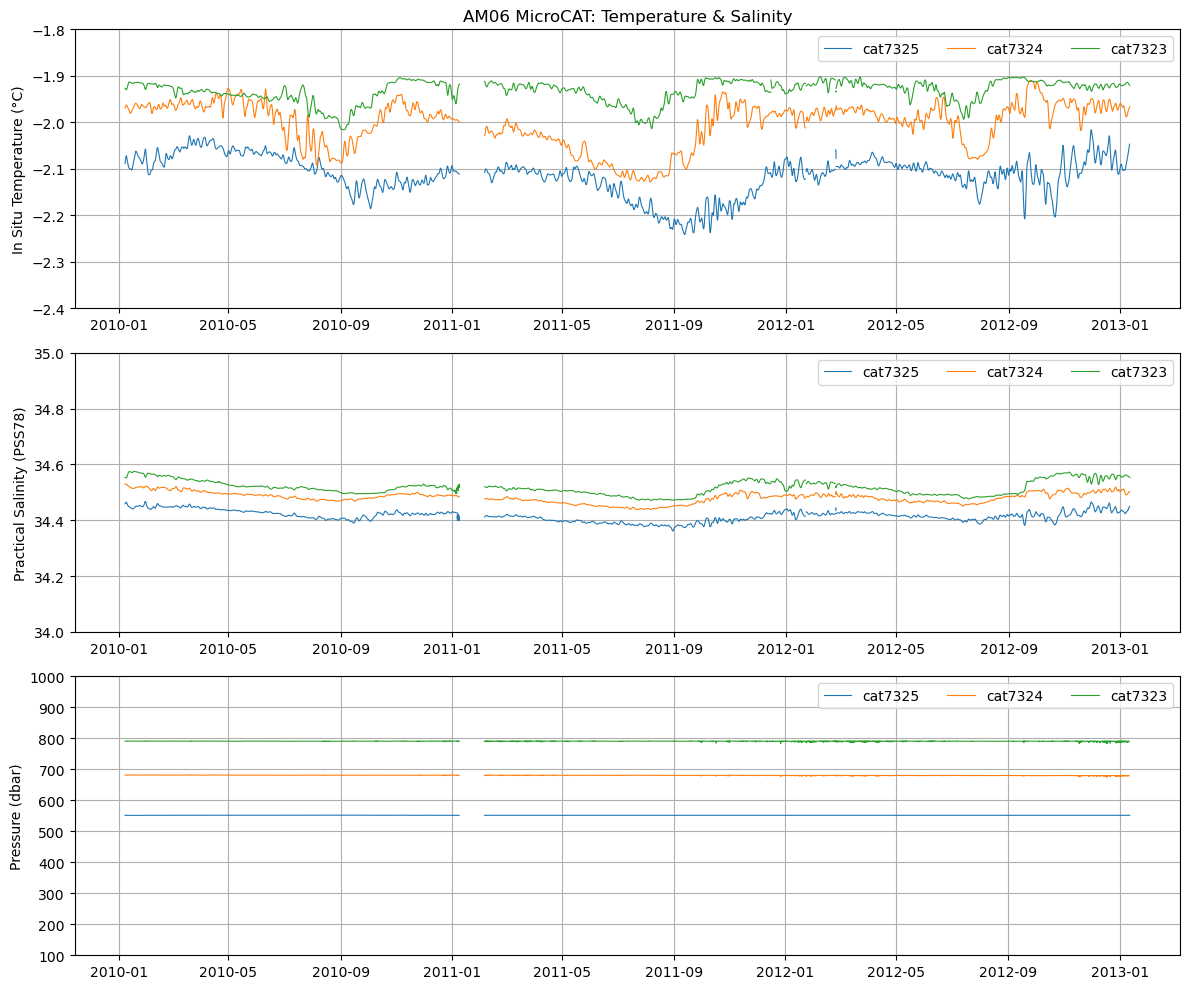

In [2]:
df = pd.read_parquet("../data/proc/04_pressure_handled.parquet")

# --- make one figure per borehole ---
boreholes = sorted(df["borehole"].unique())
for am_id in boreholes:
    plot_time_series(df, am_id, (-2.4, -1.8), (34, 35), (100, 1000), resample="None")  # change "D" to None / "H" / "7D" etc.

### <span style="color:purple"> Inspect short periods of time where pressure fluctuations occur </span>

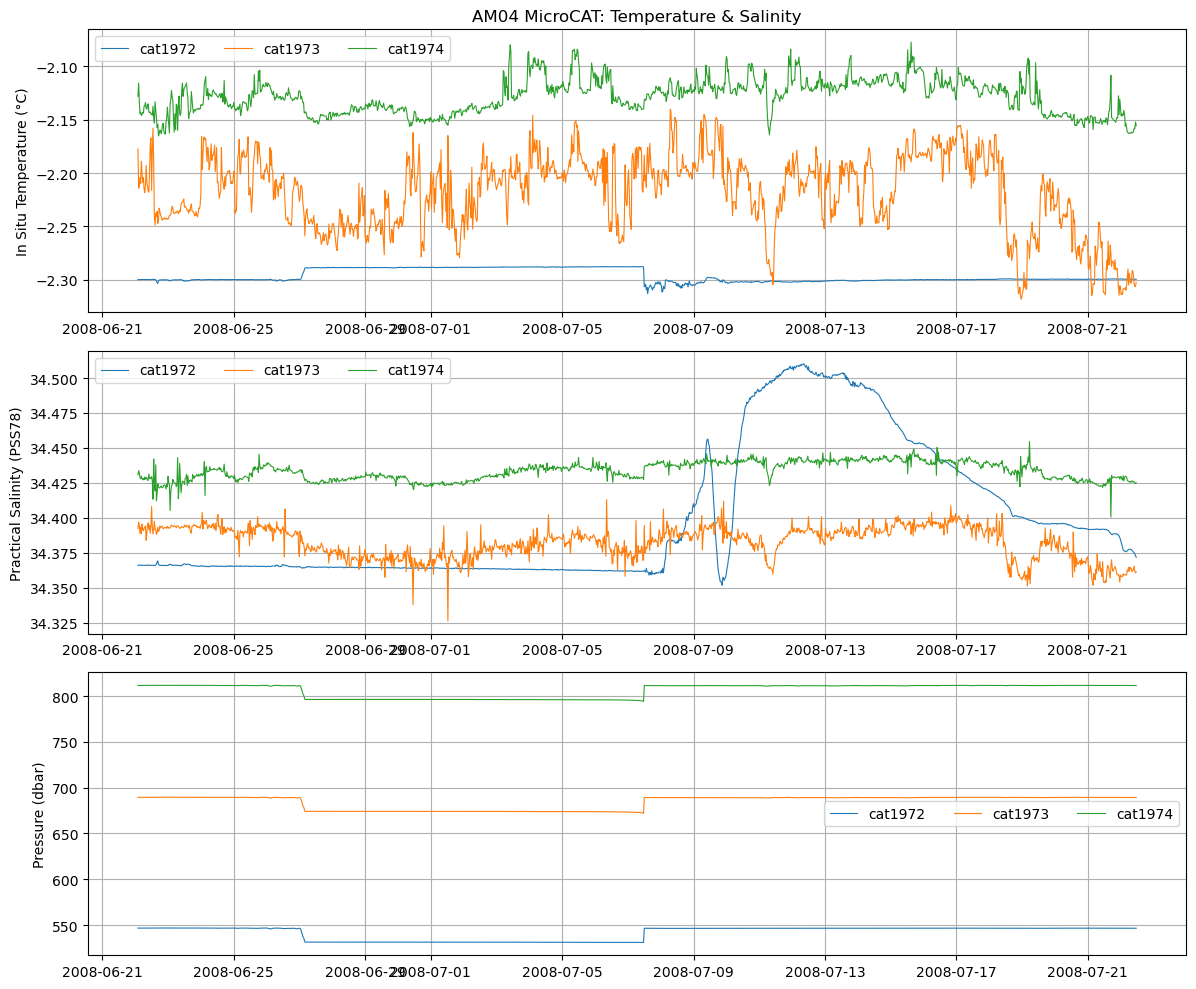

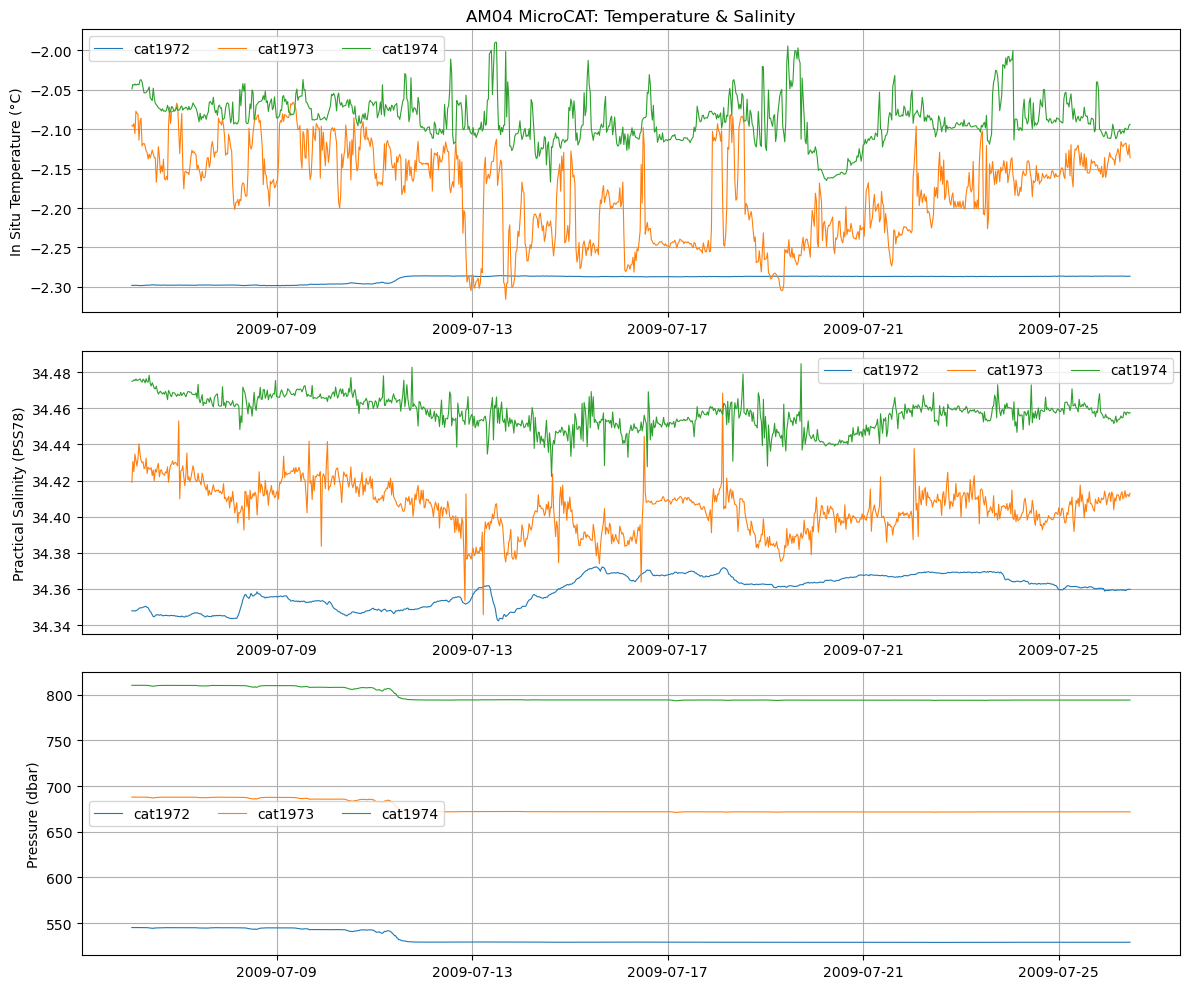

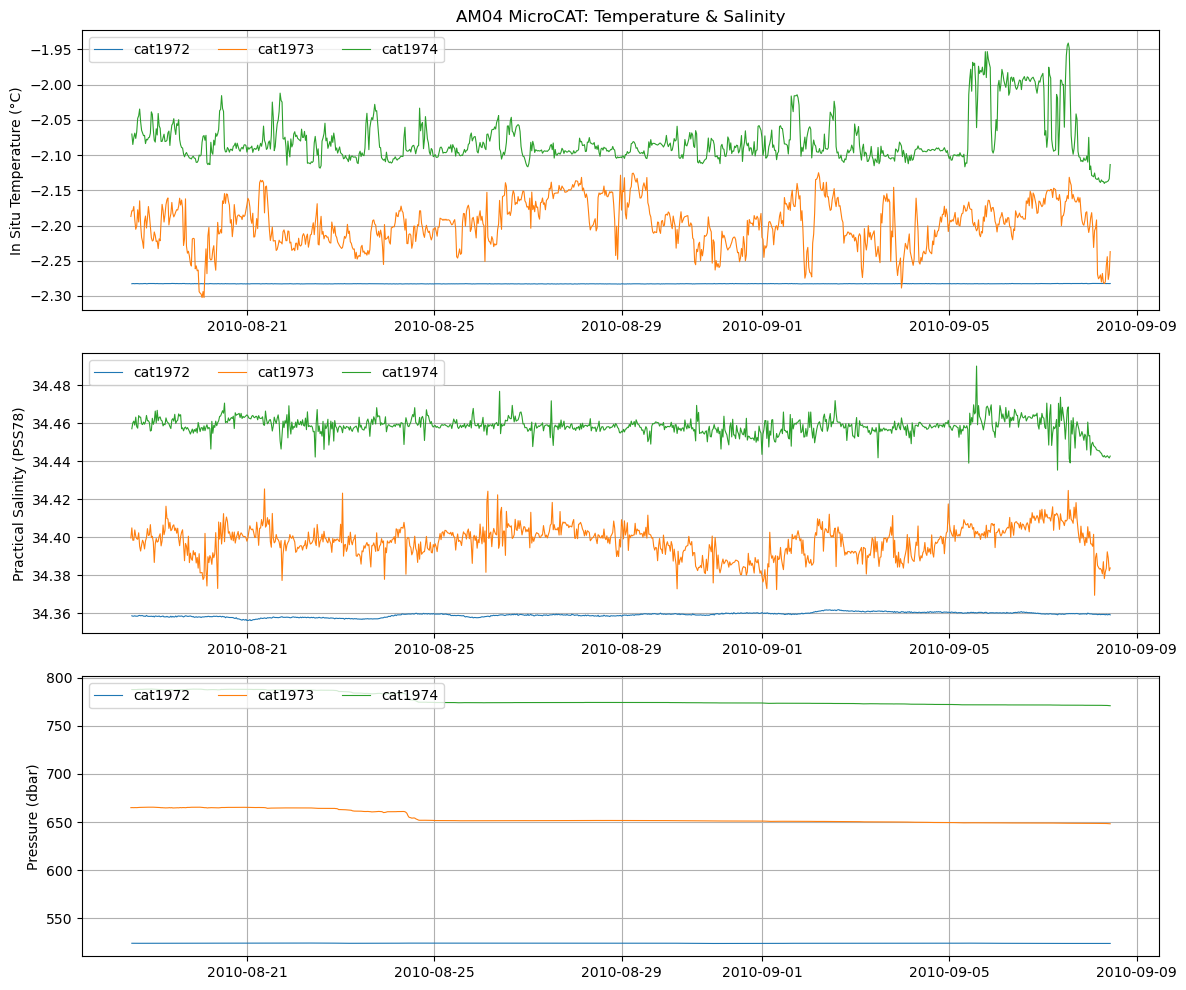

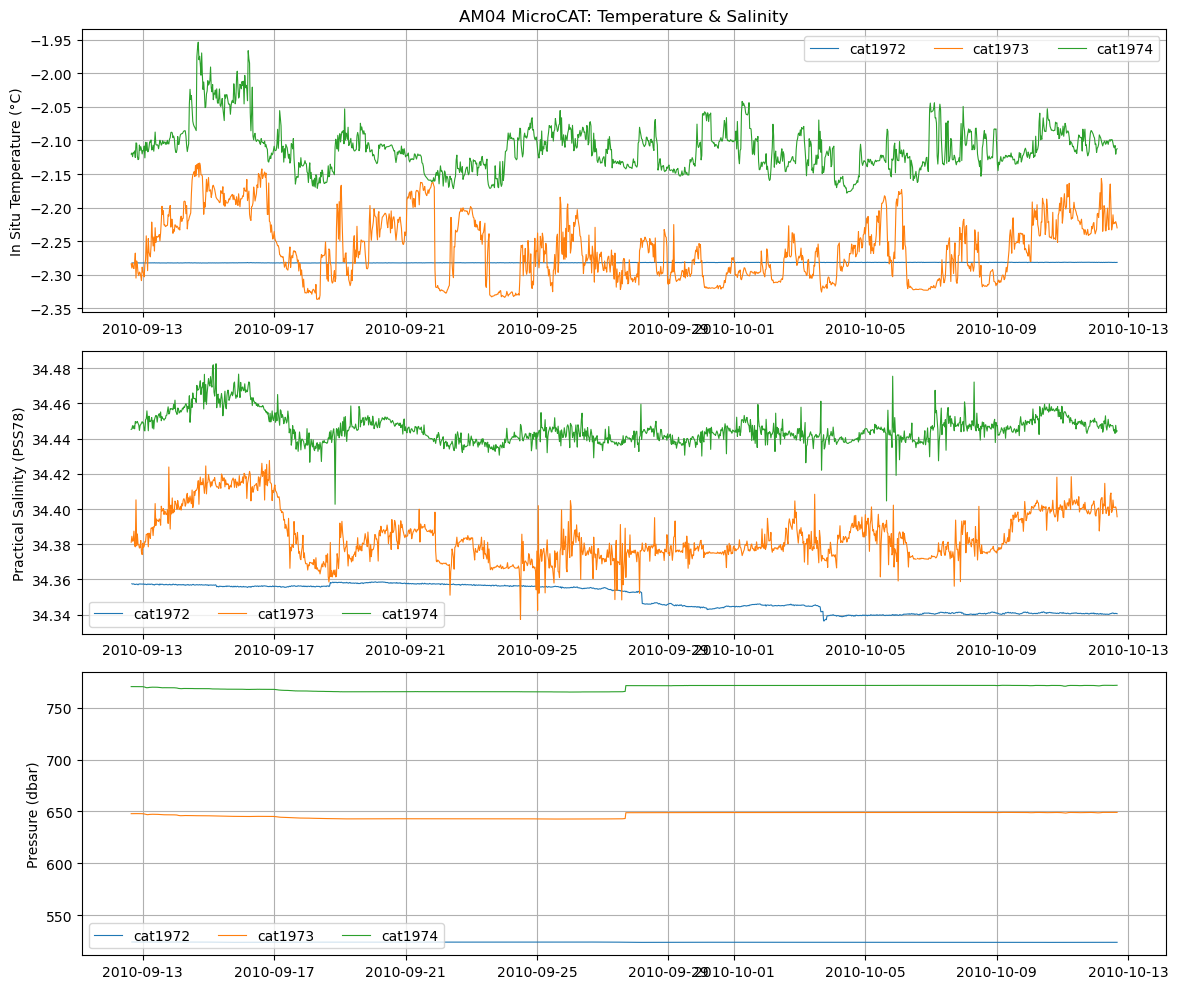

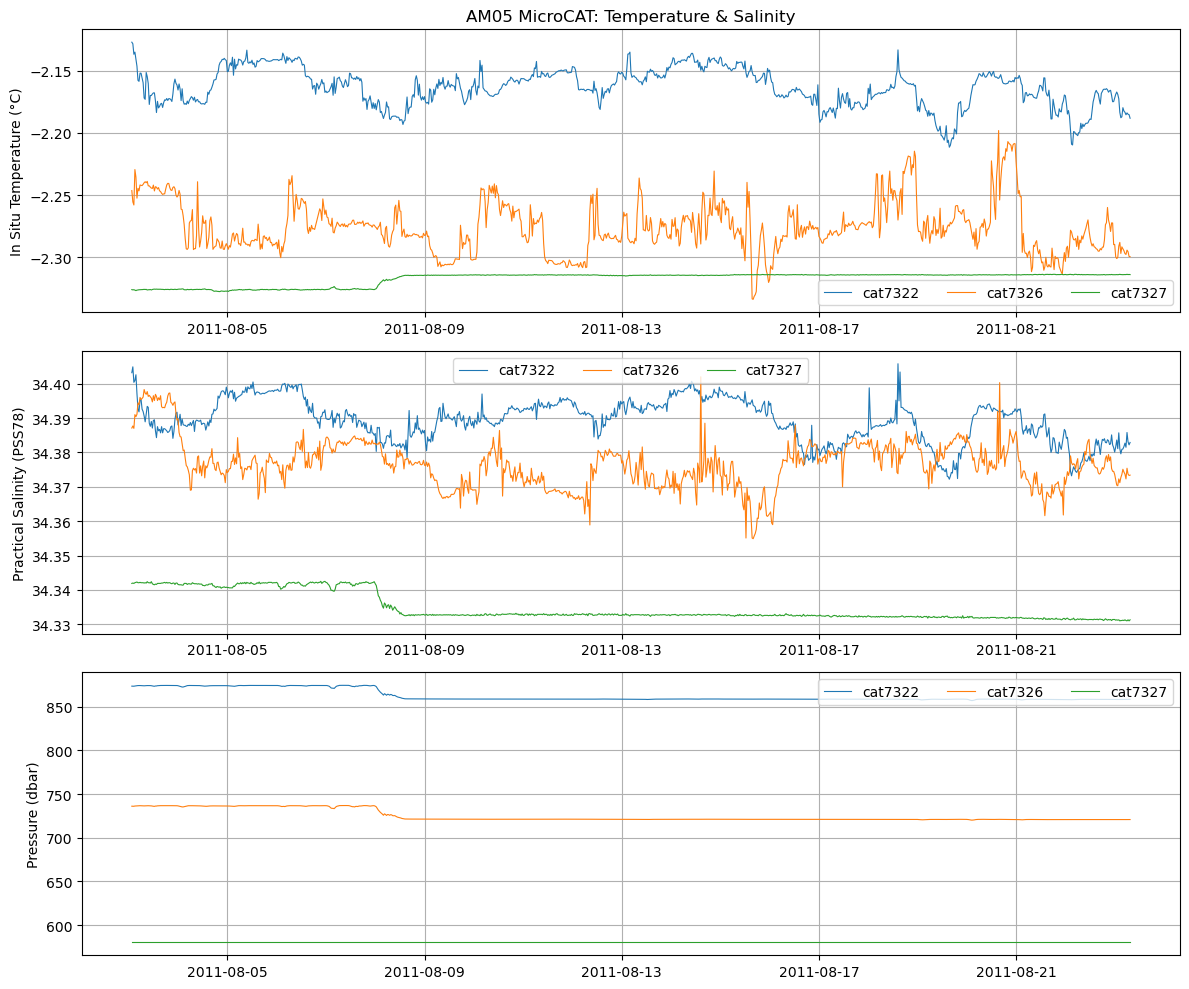

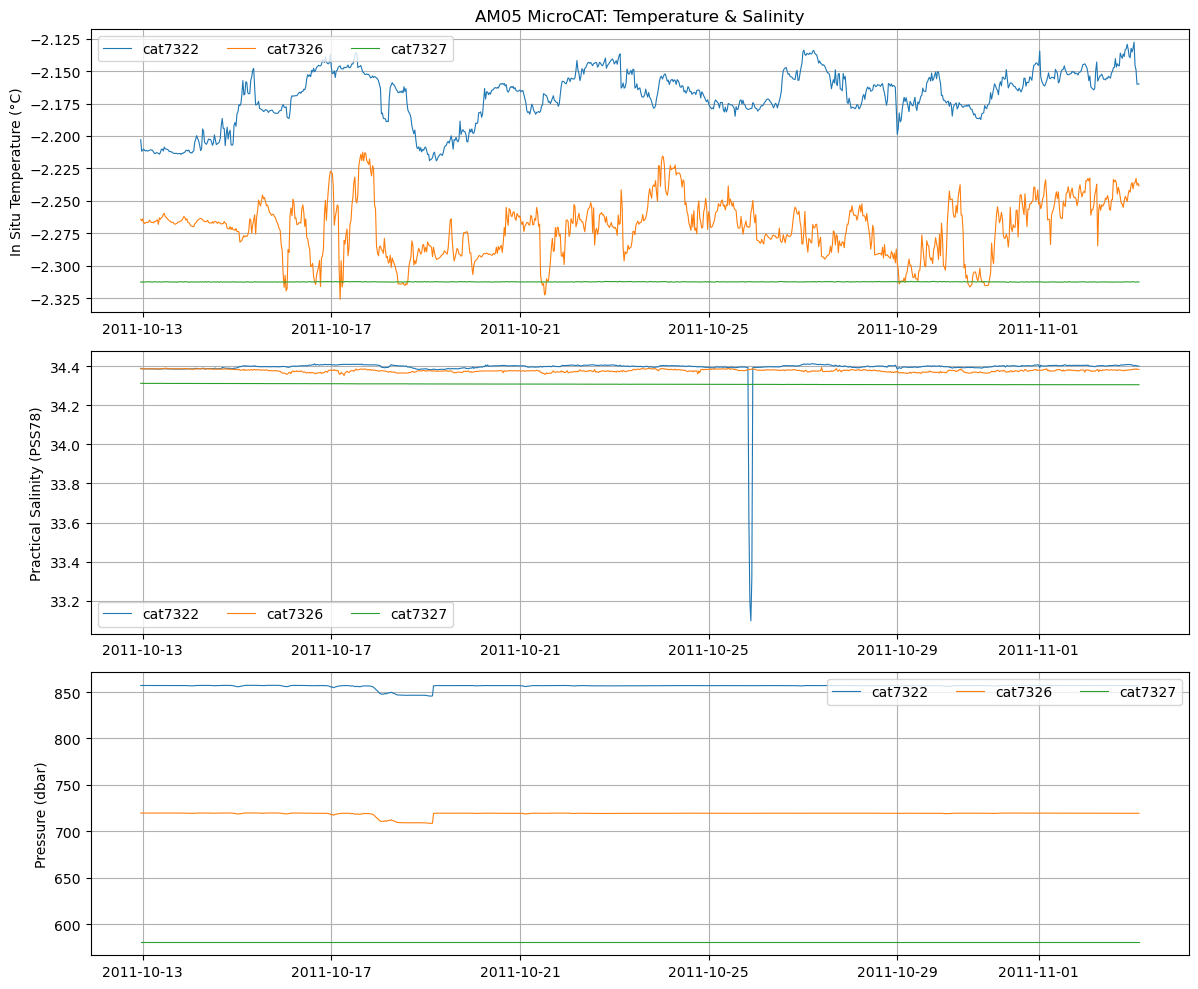

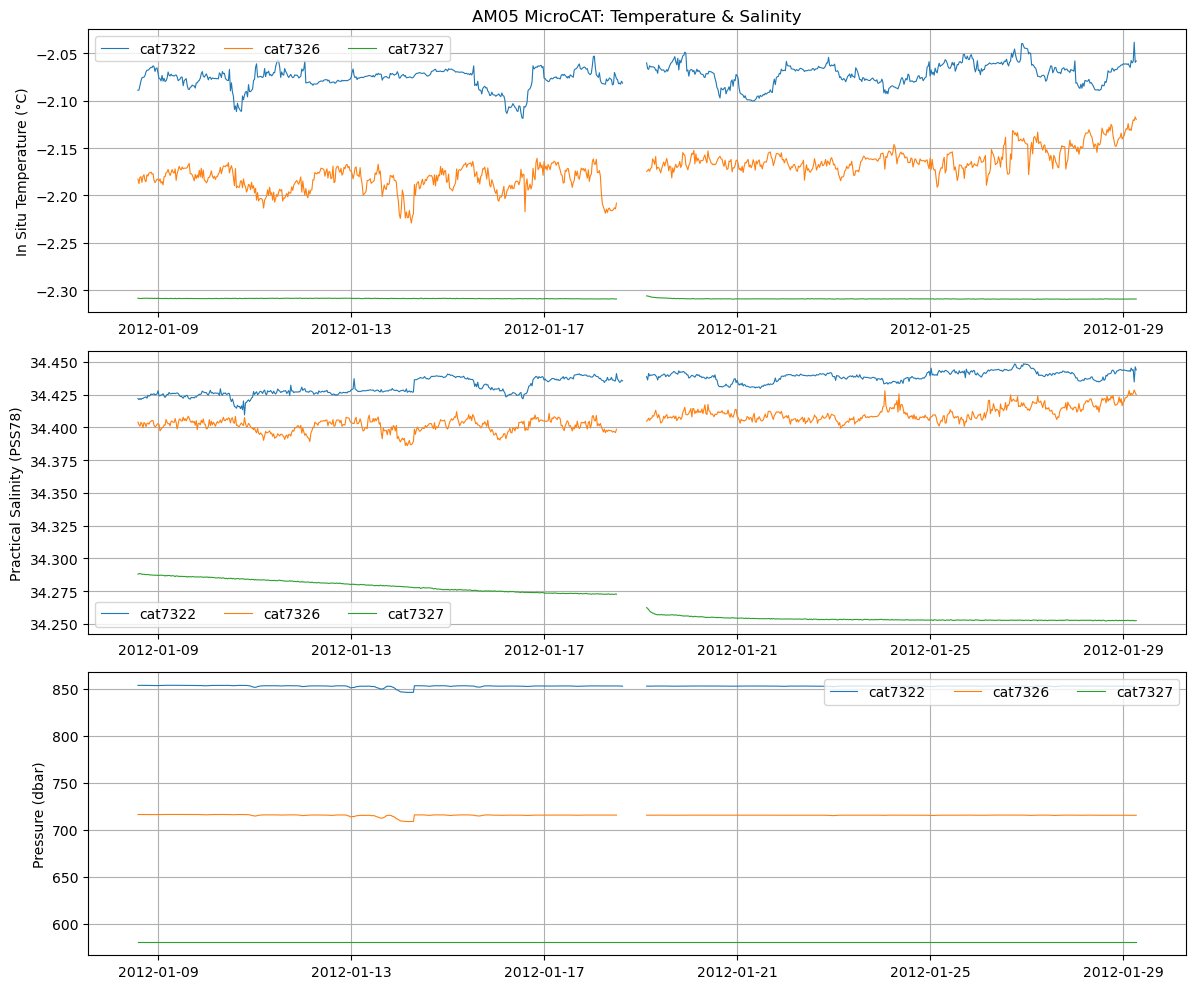

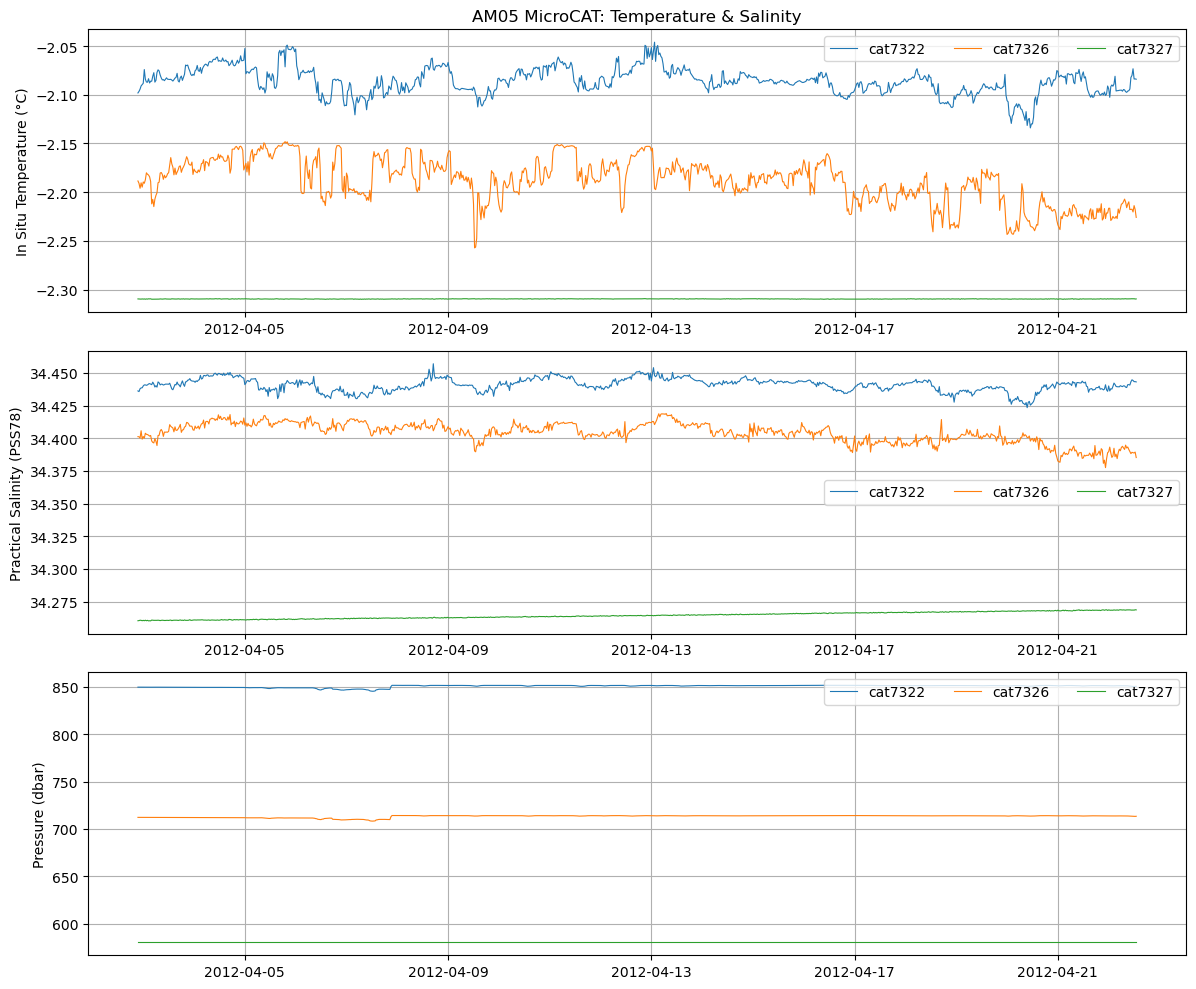

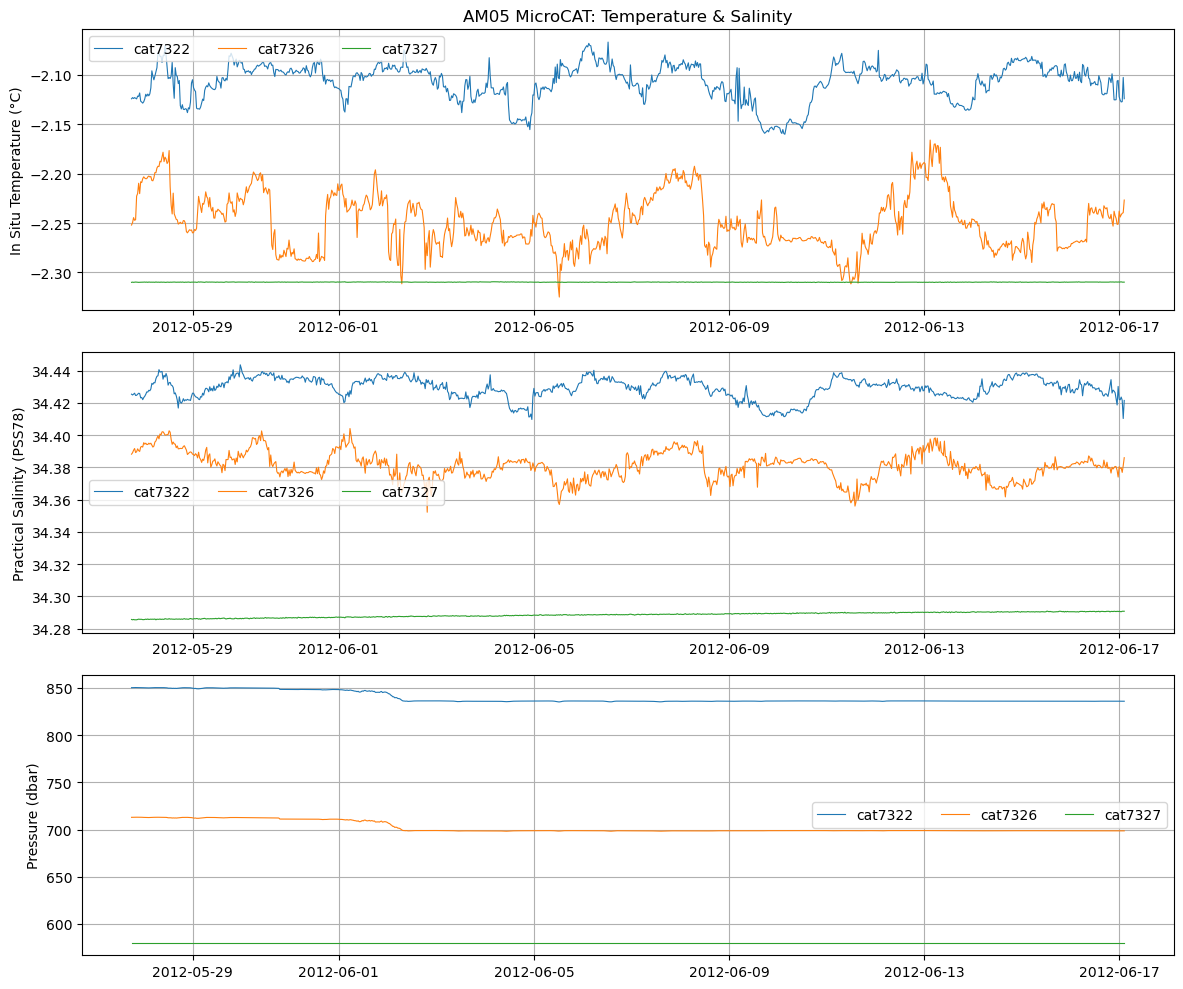

In [22]:
# Read in the identified pressure change events
events = pd.read_parquet("../data/proc/pressure_changes.parquet")

# Create a buffer of 5 days around each event
buffer_days = 5

# Iterate over each event
for i, event in events.iterrows():
    # Calculate the start and end time including the buffer
    start = event["event_start"] - pd.Timedelta(days=buffer_days)
    end = event["event_end"] + pd.Timedelta(days=buffer_days)

    plot_time_series(
        df, 
        event["borehole"],
        start_time=str(start),
        end_time=str(end)
    )